<a href="https://colab.research.google.com/github/Atherizz/PCVK_2026/blob/main/week_7/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
# MODUL P7 - SEGMENTASI CITRA DENGAN THRESHOLDING
**Mata Kuliah:** Pengolahan Citra dan Visi Komputer (PCVK)  
**Jurusan:** Teknologi Informasi - D4 Teknik Informatika

## Cell Identitas

In [ ]:
NAMA = "Savero Athallah Hardiana Putra"
NIM  = "244107020116"
KELAS = "TI-3B"
MATA_KULIAH = "Pengolahan Citra dan Visi Komputer"

print("=" * 50)
print(f"Nama        : {NAMA}")
print(f"NIM         : {NIM}")
print(f"Kelas       : {KELAS}")
print(f"Mata Kuliah : {MATA_KULIAH}")
print("=" * 50)

Nama        : Savero Athallah Hardiana Putra
NIM         : 244107020116
Kelas       : TI-3H
Mata Kuliah : Pengolahan Citra dan Visi Komputer


## Persiapan: Mount Drive & Import Library
Notebook ini dirancang adaptif: dapat dijalankan langsung di **Google Colab** maupun di **lingkungan lokal** (`.venv`).

In [2]:
import os
import sys
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import skimage
from skimage import io, data
from sklearn.cluster import KMeans

# Cek ketersediaan Google Colab
try:
    from google.colab import drive
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
    print("Berjalan di Google Colab environment")
except ImportError:
    IN_COLAB = False
    print("Berjalan di Local environment (.venv)")
    # Fungsi cv2_imshow pengganti untuk environment lokal
    def cv2_imshow(img, title=None):
        if len(img.shape) == 3:
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap="gray")
        if title:
            plt.title(title)
        plt.axis("off")
        plt.show()

# Penentuan path folder gambar yang fleksibel
if os.path.exists("week_7/images"):
    IMG_DIR = "week_7/images"
elif os.path.exists("images"):
    IMG_DIR = "images"
else:
    IMG_DIR = "/content/drive/MyDrive/PCVK/Images"

print(f"Direktori Citra Aktif: {IMG_DIR}")

Berjalan di Local environment (.venv)
Direktori Citra Aktif: images


## C. ULASAN TEORI
### C.1 Pengertian Segmentasi
Segmentasi citra adalah proses membagi sebuah citra digital menjadi beberapa area atau region yang memiliki kemiripan sifat visual seperti intensitas, warna, atau tekstur. Tujuannya adalah memisahkan bagian citra yang dianggap penting (objek/foreground) dari bagian yang kurang relevan (latar belakang/background).

| Kelompok | Prinsip | Contoh Metode |
|---|---|---|
| **Thresholding** | Memisahkan piksel dengan batas intensitas (global, lokal, otomatis). | Global, adaptive, Otsu, multi-Otsu, Triangle, Sauvola |
| **Berbasis tepi** | Mencari diskontinuitas intensitas lalu menutup kontur. | Sobel, Canny, Roberts |
| **Berbasis region** | Mengelompokkan piksel bertetangga yang homogen. | Region growing, split and merge, watershed, mean shift |
| **Clustering** | Mengelompokkan piksel di ruang fitur (warna, posisi, tekstur). | K-Means, mean shift, GMM |
| **Kontur aktif** | Kurva yang bergerak meminimalkan fungsi energi. | Snake, level set |
| **Deep learning** | Jaringan dilatih dengan citra bertanda. | U-Net, Mask R-CNN, Segment Anything Model (SAM) |

### C.2 Pengertian Operasi Thresholding
Thresholding adalah bentuk metode paling sederhana dari segmentasi citra. Persamaan dasar segmentasi biner:

$$
g(x, y) = \begin{cases} 1 & \text{jika } f(x, y) > T \\ 0 & \text{jika } f(x, y) \le T \end{cases}
$$

Ketika $T$ berupa nilai konstan untuk keseluruhan citra, proses tersebut dinamakan **Global Thresholding**. Jika $T$ berubah-ubah bergantung pada posisi lokal $(x, y)$, dinamakan **Adaptive/Variable Thresholding**.

### C.3 Global Threshold (Library OpenCV)
OpenCV menyediakan fungsi `cv.threshold(src, thresh, maxval, type)` dengan 5 tipe threshold global utama:
1. **THRESH_BINARY**: $dst(x, y) = maxVal$ jika $src(x, y) > thresh$, selain itu $0$
2. **THRESH_BINARY_INV**: $dst(x, y) = 0$ jika $src(x, y) > thresh$, selain itu $maxVal$
3. **THRESH_TRUNC**: $dst(x, y) = thresh$ jika $src(x, y) > thresh$, selain itu $src(x, y)$
4. **THRESH_TOZERO**: $dst(x, y) = src(x, y)$ jika $src(x, y) > thresh$, selain itu $0$
5. **THRESH_TOZERO_INV**: $dst(x, y) = 0$ jika $src(x, y) > thresh$, selain itu $src(x, y)$

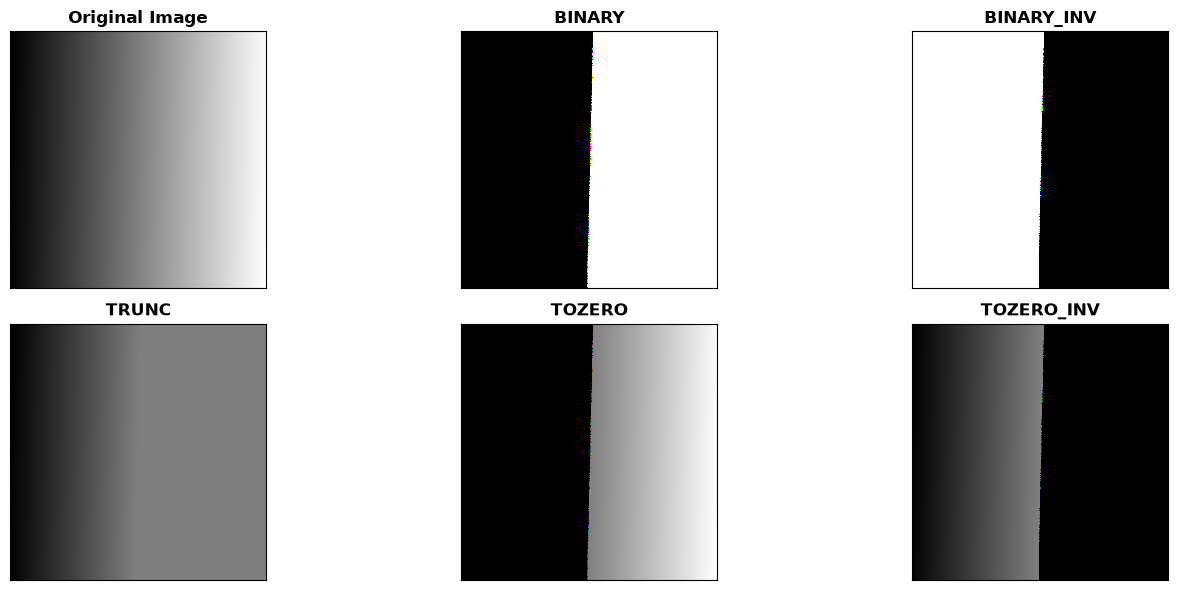

In [3]:
# Percobaan C.3: 5 Jenis Global Thresholding pada Citra Gradien
filename = os.path.join(IMG_DIR, "gradient.jpg")
img = cv.imread(filename)

if img is None:
    # Fallback pembuatan gradien sintetis
    grad = np.tile(np.linspace(0, 255, 300, dtype=np.uint8), (150, 1))
    img = cv.cvtColor(grad, cv.COLOR_GRAY2BGR)

thresh = 127
maxval = 255

# 1. Binary
ret, thresh1 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)
# 2. Binary Inverted
ret, thresh2 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY_INV)
# 3. Truncate
ret, thresh3 = cv.threshold(img, thresh, maxval, cv.THRESH_TRUNC)
# 4. To Zero
ret, thresh4 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO)
# 5. To Zero Inverted
ret, thresh5 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO_INV)

titles = ["Original Image", "BINARY", "BINARY_INV", "TRUNC", "TOZERO", "TOZERO_INV"]
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 6))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], "gray", interpolation="nearest")
    plt.title(titles[i], fontsize=12, fontweight="bold")
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

### C.4 Adaptive Threshold (Library OpenCV)
Pada citra dengan pencahayaan tidak merata (misalnya ada bayangan atau gradien cahaya), satu nilai ambang global $T$ sering gagal. Adaptive thresholding menghitung nilai ambang $T(x, y)$ secara dinamis berdasarkan jendela lokal berukuran $b \times b$ di sekitar tiap piksel.

Dua metode utama di OpenCV:
- **`cv.ADAPTIVE_THRESH_MEAN_C`**: Ambang dihitung dari rata-rata jendela dikurangi konstanta $C$.
- **`cv.ADAPTIVE_THRESH_GAUSSIAN_C`**: Ambang dihitung dari rata-rata berbobot Gaussian dikurangi konstanta $C$.

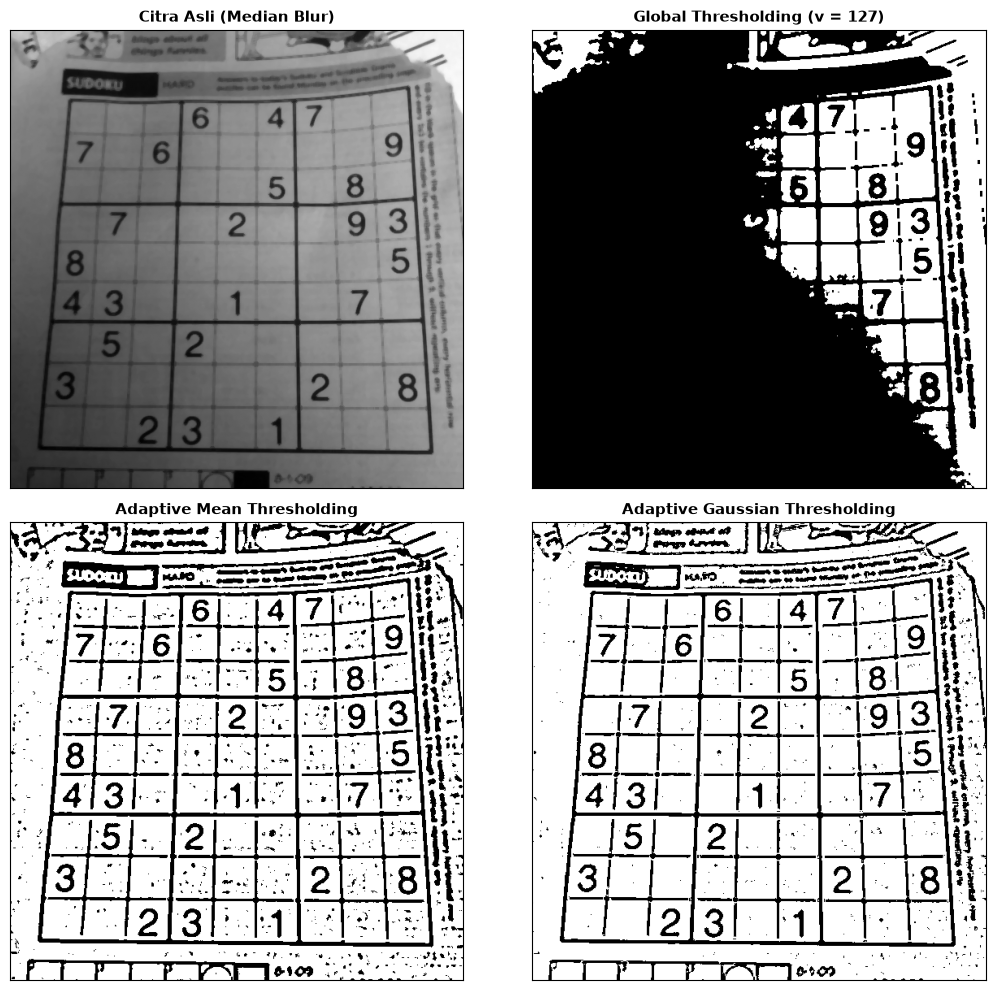

In [4]:
# Percobaan C.4: Adaptive Thresholding pada Citra Sudoku
filename = os.path.join(IMG_DIR, "sudoku-original.jpg")
raw = cv.imread(filename)
if raw is None:
    raise FileNotFoundError(f"Citra {filename} tidak ditemukan.")

citra = cv.medianBlur(raw, 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)
thresh = 127

# Global Thresholding
ret, th1 = cv.threshold(gray, thresh, 255, cv.THRESH_BINARY)
# Adaptive Mean
th2 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)
# Adaptive Gaussian
th3 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

titles = ["Citra Asli (Median Blur)", "Global Thresholding (v = 127)",
          "Adaptive Mean Thresholding", "Adaptive Gaussian Thresholding"]
citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(11, 10))
for i in range(len(citra2)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(citra2[i], "gray")
    plt.title(titles[i], fontsize=11, fontweight="bold")
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

### C.5 Otsu's Thresholding (Library OpenCV)
Algoritma Otsu secara otomatis menentukan nilai ambang optimal dengan meminimalkan variansi intra-kelas (within-class variance $\sigma_w^2$) atau memaksimalkan variansi antar-kelas (between-class variance $\sigma_B^2$).

$$\sigma_B^2 = \omega_b \omega_f (\mu_b - \mu_f)^2$$

Berikut pengujian Otsu pada citra berkontras rendah (`lena_gs_lc2.jpg`) di mana global thresholding 127 gagal total.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_2956\3738401389.py:16: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(blur.ravel(), 256, [50, 200], color="skyblue", edgecolor="black")


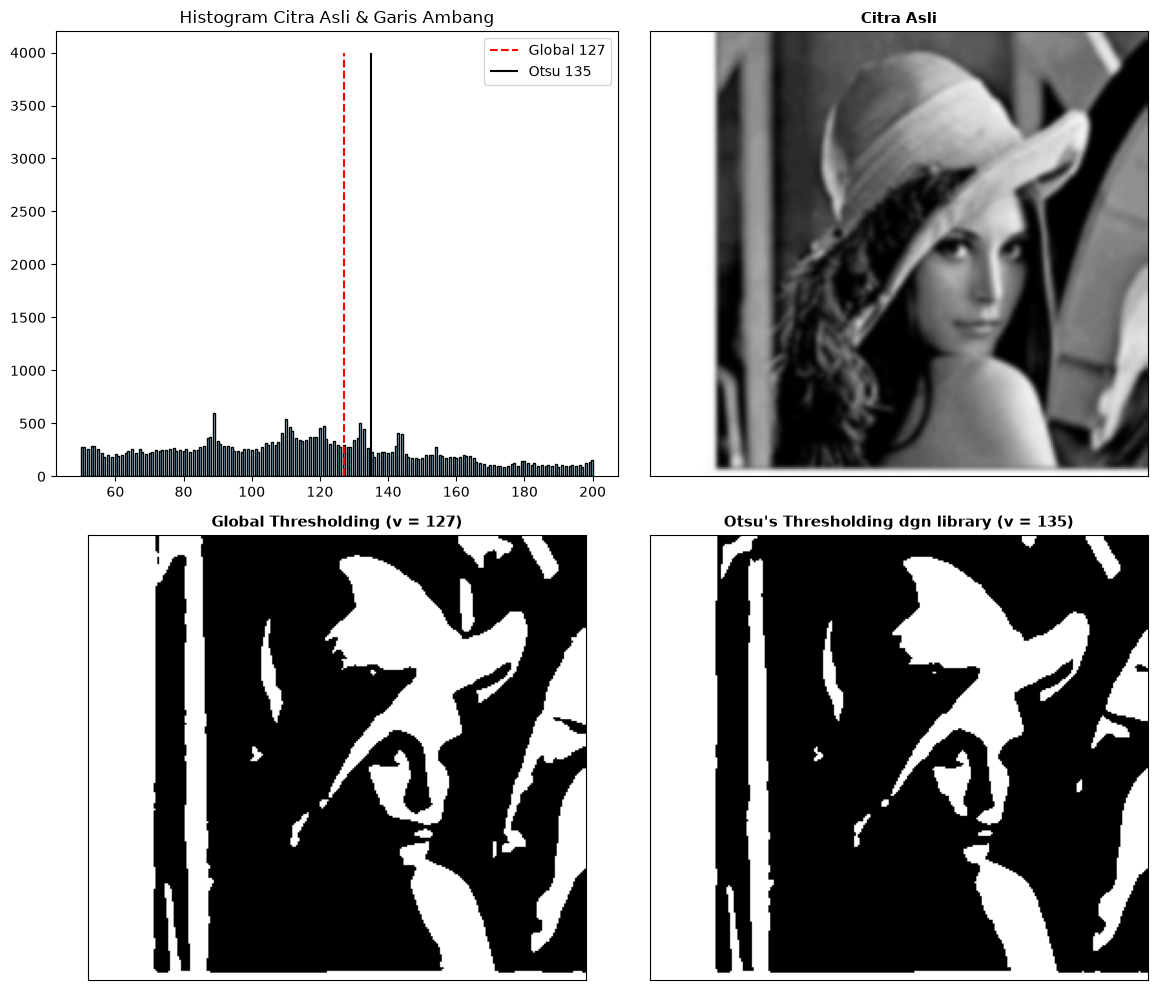

In [5]:
# Percobaan C.5.1: Otsu pada Citra Low-Contrast (lena_gs_lc2.jpg)
filename = os.path.join(IMG_DIR, "lena_gs_lc2.jpg")
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
ret2, th2 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

x = f"Otsu's Thresholding dgn library (v = {int(ret2)})"
titles = ["Citra Asli", "Global Thresholding (v = 127)", x]
citra3 = [blur, th1, th2]

plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1)
plt.hist(blur.ravel(), 256, [50, 200], color="skyblue", edgecolor="black")
plt.vlines(ret, 0, 4000, colors="red", linestyles="--", label=f"Global {thresh}")
plt.vlines(ret2, 0, 4000, colors="black", linestyles="-", label=f"Otsu {int(ret2)}")
plt.title("Histogram Citra Asli & Garis Ambang")
plt.legend()

for i in range(len(citra3)):
    plt.subplot(2, 2, i + 2)
    plt.imshow(citra3[i], "gray")
    plt.title(titles[i], fontsize=11, fontweight="bold")
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

#### Otsu's Thresholding pada Citra Bernoise (`noisy2.png`)
Membandingkan efektivitas Otsu sebelum dan sesudah diaplikasikan Gaussian Filter untuk meredam noise bimodal.

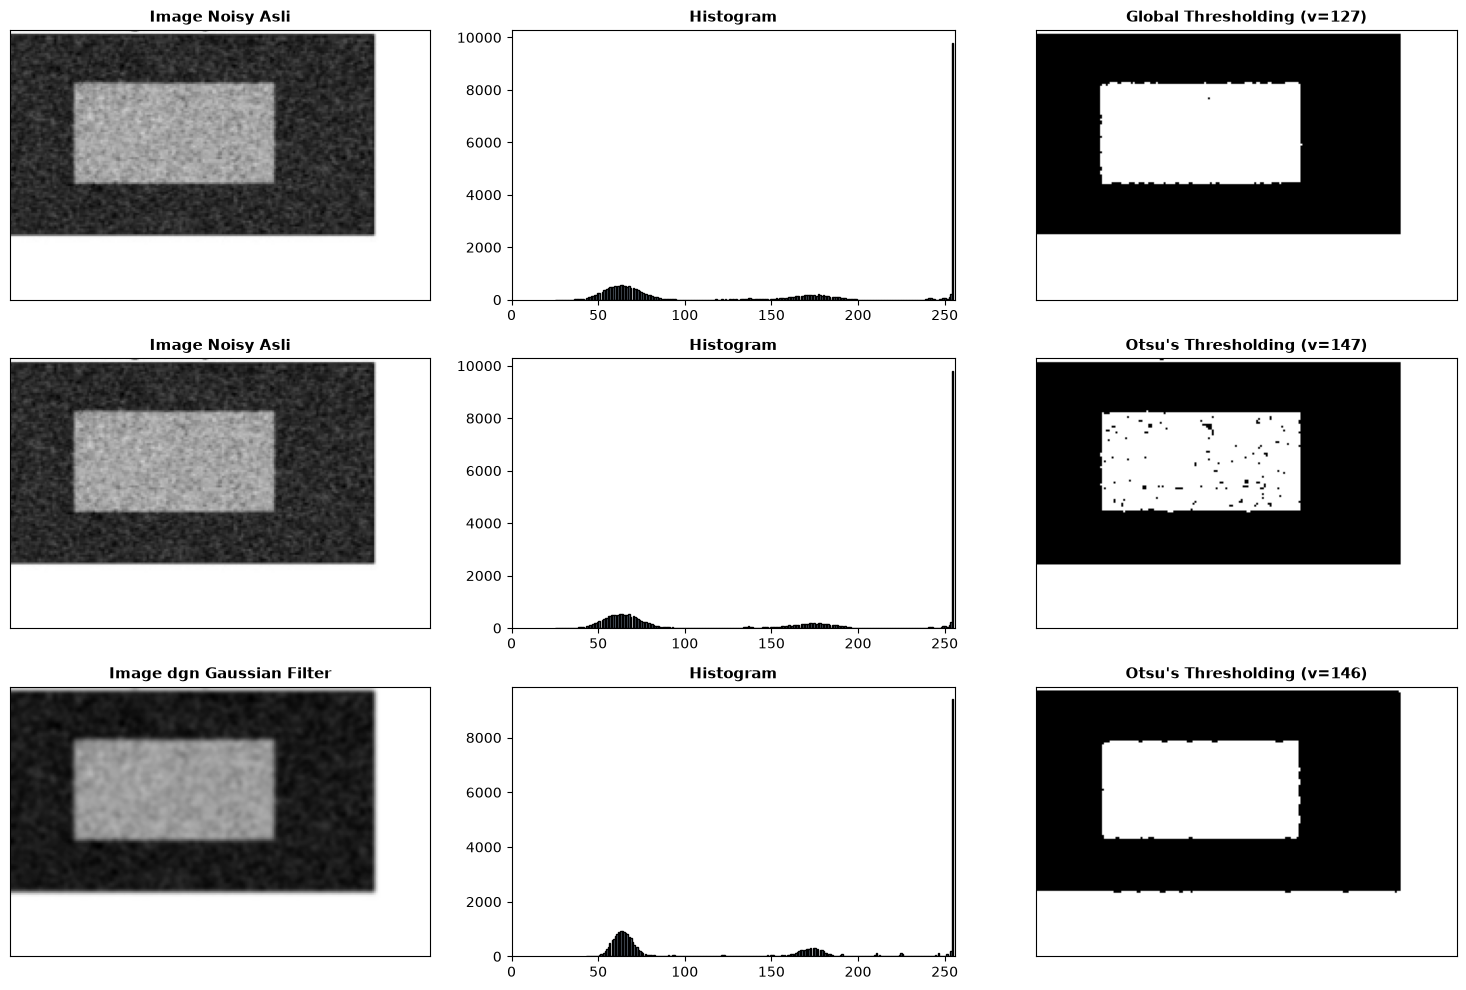

In [6]:
# Percobaan C.5.2: Otsu dengan dan tanpa Gaussian Filtering pada noisy2.png
filename = os.path.join(IMG_DIR, "noisy2.png")
img = cv.imread(filename, 0)

# Global Thresholding
ret1, th1 = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
# Otsu thresholding tanpa filtering
ret2, th2 = cv.threshold(img, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
# Otsu thresholding setelah Gaussian filtering
blur = cv.GaussianBlur(img, (5, 5), 0)
ret3, th3 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

images = [img, 0, th1,
          img, 0, th2,
          blur, 0, th3]
titles = ["Image Noisy Asli", "Histogram", "Global Thresholding (v=127)",
          "Image Noisy Asli", "Histogram", f"Otsu's Thresholding (v={int(ret2)})",
          "Image dgn Gaussian Filter", "Histogram", f"Otsu's Thresholding (v={int(ret3)})"]

plt.figure(figsize=(15, 10))
for i in range(3):
    plt.subplot(3, 3, i * 3 + 1)
    plt.imshow(images[i * 3], "gray")
    plt.title(titles[i * 3], fontsize=11, fontweight="bold")
    plt.xticks([]), plt.yticks([])

    plt.subplot(3, 3, i * 3 + 2)
    plt.hist(images[i * 3].ravel(), 256, color="slategray", edgecolor="black")
    plt.title(titles[i * 3 + 1], fontsize=11, fontweight="bold")
    plt.xlim([0, 256])

    plt.subplot(3, 3, i * 3 + 3)
    plt.imshow(images[i * 3 + 2], "gray")
    plt.title(titles[i * 3 + 2], fontsize=11, fontweight="bold")
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

### C.6 Segmentasi Citra Berbasis Wilayah (Region-Based Segmentation)
Alih-alih bertanya *"apakah nilai piksel ini di atas atau di bawah ambang?"*, metode berbasis wilayah bertanya *"apakah piksel ini mirip dengan tetangga-tetangganya?"*.

**Syarat Formal Segmentasi Wilayah:**
1. **Lengkap**: $\bigcup_{i=1}^n R_i = I$
2. **Terhubung**: Tiap $R_i$ saling bersambungan secara spasial.
3. **Saling lepas**: $R_i \cap R_j = \emptyset$ untuk $i \ne j$
4. **Homogen**: $P(R_i) = \text{TRUE}$
5. **Berbeda antar region**: $P(R_i \cup R_j) = \text{FALSE}$ untuk region bertetangga.

| Metode | Prinsip Utama | Perlu Seed/Marker | Kelebihan | Kekurangan |
|---|---|---|---|---|
| **Region Growing** | Menumbuhkan region dari seed berdasarkan kemiripan intensitas | Ya (seed) | Sederhana, region terhubung | Sensitif terhadap seed dan noise |
| **Split & Merge** | Membagi kuadran (quadtree) lalu menggabungkan blok homogen | Tidak | Otomatis tanpa seed | Batas region cenderung kotak-kotak |
| **Watershed** | Analogi topografi banjir dari marker | Ya (marker) | Unggul memisahkan objek bersentuhan | Over-segmentation tanpa marker |
| **Mean Shift** | Mencari puncak densitas mode di ruang fitur | Tidak | Jumlah cluster otomatis, tepi tajam | Komputasi berat |

### C.7 Segmentasi Citra Menggunakan K-Means Clustering
K-Means mengelompokkan piksel citra di ruang warna tanpa memperhatikan posisi spasial piksel, sehingga sering disebut teknik **kuantisasi warna** (*color quantization*).

Fungsi objektif meminimalkan inersia (Within-Cluster Sum of Squares):
$$J = \sum_{k=1}^K \sum_{x_i \in C_k} ||x_i - \mu_k||^2$$

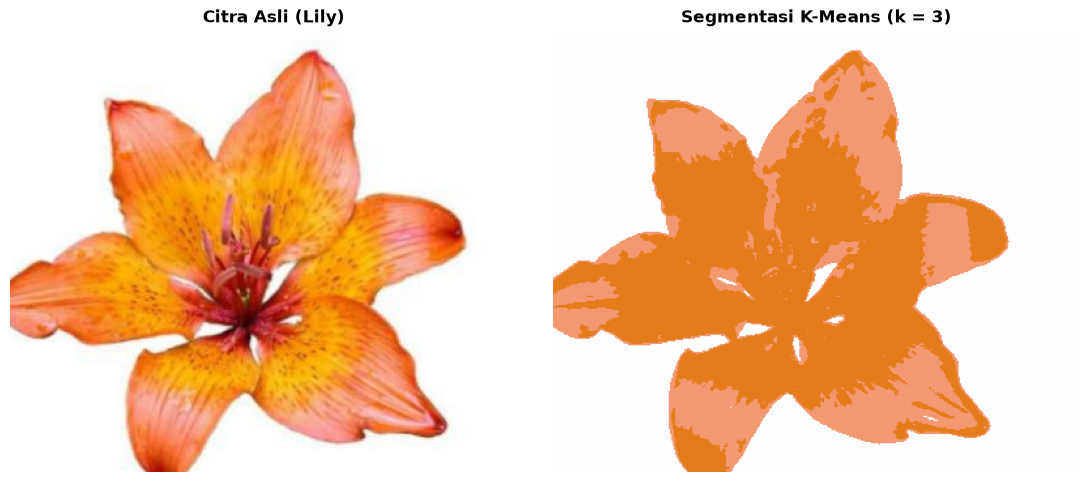

In [7]:
# Percobaan C.7: Segmentasi Warna Citra Bunga Lily dengan K-Means
filename = os.path.join(IMG_DIR, "lily.jpg")
img_bgr = cv.imread(filename)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# Ubah citra menjadi matriks 2D (piksel, 3 kanal RGB)
Z = img_rgb.reshape((-1, 3))
Z = np.float32(Z)

# Tentukan jumlah cluster K = 3
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)

# Ambil label cluster dan centroid warna
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

# Bentuk citra hasil segmentasi warna
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img_rgb.shape)

# Visualisasi
plt.figure(figsize=(11, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Citra Asli (Lily)", fontsize=12, fontweight="bold")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented_img)
plt.title(f"Segmentasi K-Means (k = {k})", fontsize=12, fontweight="bold")
plt.axis("off")

plt.tight_layout()
plt.show()